# Supplementary Fig. 5e: training loss of the CEBRA model

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel e of Supplementary Fig. 5: InfoNCE training loss of the CEBRA model (full waveforms + quality metrics, spontaneous regime, Kilosort4) as a function of the training iterations, for each of the 100 cross-validated samples (grey lines). It shows that the loss converged. Source data and svg are saved in figures/8_source_data/supp_fig5e/.

**prerequisites**: the `spikebias` environment with `cebra==0.4.0` and `scikit-learn==1.5.2` (the versions pinned in `envs/cebraspike.txt`; cebra 0.4.0 does not work with scikit-learn 1.6 and later) and `literate-dataclasses`; a GPU makes the training faster (about 15 minutes for 100 folds of 100 iterations on an RTX 5090).

**method**: the dataset, the model and the 100 cross-validated samples are those of supp_fig5c.ipynb, trained for 100 iterations (the x-axis of the paper's panel goes to 100 iterations; panel c is trained for 40 iterations); the loss of each sample is the loss of the model at each iteration (`solver_.history`).

In [1]:
# SETUP PACKAGES
import os
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from matplotlib import pyplot as plt
warnings.simplefilter(action="ignore")

# SET PROJECT PATH
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias"
os.chdir(PROJ_PATH)
from src.nodes.models.CebraSpike import dataloader as cs_dataloader
from src.nodes.models.CebraSpike.models import CebraSpike

# DATA: 10 minutes of the spontaneous regime sorted with Kilosort4
QUALITY_PATH = "dataset/01_intermediate/quality/sorting_quality.csv"
SORTING_PATH = "dataset/01_intermediate/sorting/npx_spont/SortingKS4_10m"
GROUND_TRUTH_PATH = "dataset/00_raw/ground_truth_npx_spont_10m"
WAVEFORMS_PATH = "dataset/01_intermediate/waveforms/npx_spont/SortingKS4_10m_single_units"      # waveforms of the sorted single-units (first 10 minutes, see fig5e.ipynb)
EXP, SORTER = "NS", "KS4"
MODEL_PATH = "models/cebra/spont_100_iterations/"     # weights of the 100 cross-validated models (.pt) and folds.csv

# MODEL PARAMETERS
N_ITERATIONS = 100          # training iterations
N_SPIKES = 25               # spikes per unit
INTERVAL_MS = 3             # waveform window: +/- 3 ms around the spike peak (240 samples at 40 kHz)
N_NEIGHBORS = 20            # k-nearest neighbor decoder
SEEDS = np.arange(0, 100, 1)

# FIGURE SETTINGS
plt.rcParams["font.family"] = "DejaVu Sans"   # the paper's figure was drawn without Arial (matplotlib default font)
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
savefig_cfg = {"transparent": True, "dpi": 300}

In [ ]:
# Nature figure guidelines for every saved figure: Arial, 5-7 pt, editable text, images of at least 300 dpi, a .pdf next to each .svg
import os, sys
sys.path.insert(0, os.getcwd())     # the repository (the notebook moved there above)
from src.nodes import figure_style
figure_style.apply()

## Load the dataset

In [2]:
%%time

data_cs = cs_dataloader.load_dataset(qpath=QUALITY_PATH, sorting_path=SORTING_PATH, sortingtrue_path=GROUND_TRUTH_PATH, study_path=WAVEFORMS_PATH, study_singleu_path=WAVEFORMS_PATH,
                                     exp=EXP, sorter=SORTER, n_site=384, num_spikes=N_SPIKES, interval_ms=INTERVAL_MS, downsampling=1, load_we_if_exists=True, load_amp_if_exists=True, load_qmetrics_if_exists=False)
dataset = data_cs["dataset"]
print("units:", dataset["data"].shape[0], "| good:", int(dataset["label"].sum()), "| features:", dataset["data"].shape[1])

2026-11-03 09:45:27,268 - root - dataloader.py - load_dataset - INFO - Starting loading dataset..


2026-11-03 09:45:27,269 - root - dataloader.py - load_dataset - INFO - Computing sorted unit quality metrics..


  0%|          | 0/184 [00:00<?, ?it/s]

****************** Analysing data completion ***************
quality metrics are: Index(['amplitude_cutoff', 'firing_range', 'firing_rate',
       'isi_violations_ratio', 'presence_ratio', 'rp_contamination',
       'rp_violations', 'sd_ratio', 'snr', 'silhouette', 'mad_ratio'],
      dtype='object')
Data completion: amplitude_cutoff        184
firing_range            184
firing_rate             184
isi_violations_ratio    184
presence_ratio          184
rp_contamination        184
rp_violations           184
sd_ratio                184
snr                     184
silhouette              182
mad_ratio               184
dtype: int64
Dropping units with missing metrics...
nb of units before curation: 184
nb of units after curation: 182
2026-11-03 09:45:43,927 - root - dataloader.py - load_dataset - INFO - Computed quality metrics


Recording sampling frequency: 40000.0


ex. dataset shape (L4): (26, 6000)
ex. label shape (L4): (26,)

unit sample size:

L1:  1 units
L23:  2 units
L4:  26 units
L5:  116 units
L6:  39 units

********** DATASET STATS **********:


unit count:

l1: 0
l23: 1
l4: 26
l5: 116
l6: 39
units: 182 | good: 84 | features: 6011
CPU times: user 13 s, sys: 4.44 s, total: 17.4 s
Wall time: 18.3 s


## Train the CEBRA model on the 100 cross-validated samples (about 15 minutes)

In [3]:
%%time

torch.manual_seed(0)       # reproducibility
csmodel = CebraSpike(cfg={
    "model_architecture": "offset10-model",   # receptive field of size 10
    "distance": "cosine",                     # adapted to contrastive learning
    "batch_size": dataset["data"].shape[1],
    "temperature_mode": "auto",
    "learning_rate": 0.001,
    "max_iterations": N_ITERATIONS,
    "conditional": "time_delta",
    "time_offsets": 10,
    "output_dimension": 3,
    "device": "cuda_if_available",
    "verbose": False})
os.makedirs(MODEL_PATH, exist_ok=True)
results = csmodel.evaluate(dataset, MODEL_PATH, is_train=True, seeds=SEEDS, n_neighbors=N_NEIGHBORS)
stats_ = results["metric_stats"]
print(f"precision median {stats_['precision_median']:.3f} (95% CI {stats_['precision_ci95']:.3f}), recall median {stats_['recall_median']:.3f} (95% CI {stats_['recall_ci95']:.3f})")

precision median 0.604 (95% CI 0.026), recall median 0.824 (95% CI 0.029)
CPU times: user 13min 5s, sys: 704 ms, total: 13min 6s
Wall time: 13min 1s


## Source data: loss of each sample

In [4]:
# source data: loss of each cross-validated sample at each iteration
df = pd.DataFrame([{"sample": i, "iteration": it + 1, "infonce_loss": float(loss)}
                   for i, m in enumerate(results["metric_data"]) for it, loss in enumerate(m["model"]["model"].solver_.history)])
display(df.groupby("sample")["infonce_loss"].agg(["first", "last"]).describe().loc[["min", "50%", "max"]].round(3))

,first,last
min,8.685,8.113
50%,8.723,8.116
max,8.868,8.119


## Plot, same as the paper's panel e

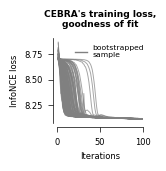

In [5]:
def plot_source_data(df: pd.DataFrame):
    """InfoNCE training loss of the CEBRA model at each iteration for each of the 100 cross-validated samples (grey lines)"""

    fig, ax = plt.subplots(1, 1, figsize=(1.1, 1.1))
    for _, d in df.groupby("sample"):
        ax.plot(d["iteration"], d["infonce_loss"], color="grey", alpha=0.7, linewidth=0.7)

    # disconnect axes (R style)
    ax.spines[["right", "top"]].set_visible(False)
    ax.spines["bottom"].set_position(("axes", -0.05))
    ax.yaxis.set_ticks_position("left")
    ax.spines["left"].set_position(("axes", -0.05))
    ax.set_xlim([0, 100])
    ax.set_xticks([0, 50, 100])
    ax.set_yticks([8.25, 8.50, 8.75], ["8.25", "8.50", "8.75"])
    ax.set_xlabel("Iterations")
    ax.set_ylabel("InfoNCE loss")
    ax.set_title("CEBRA's training loss,\ngoodness of fit", fontweight="bold", fontsize=6.5, pad=8)
    ax.plot([], [], color="grey", linewidth=1, label="bootstrapped\nsample")
    ax.legend(frameon=False, loc="upper right", fontsize=5.5, handlelength=1.5, bbox_to_anchor=(1.1, 1.0))
    return fig, ax


fig, ax = plot_source_data(df)

## Save the figure and the source data

In [6]:
os.makedirs("figures/8_source_data/supp_fig5e", exist_ok=True)
fig.savefig("figures/8_source_data/supp_fig5e/supp_fig5e.svg", bbox_inches="tight", **savefig_cfg)
df.to_excel("figures/8_source_data/supp_fig5e/supp_fig5e.xlsx", index=False)

<Figure size 640x480 with 0 Axes>

## Check: replot from the saved source data

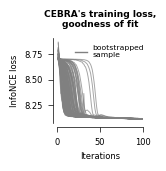

In [7]:
df_loaded = pd.read_excel("figures/8_source_data/supp_fig5e/supp_fig5e.xlsx")
fig, ax = plot_source_data(df_loaded)